# Car Price Prediction using Machine Learning

## Project Overview

This project focuses on predicting the price of cars using machine learning techniques.

The dataset contains information about different cars, including brand, manufacturing year, engine size, fuel type, transmission, mileage, condition, and model.

The project follows a complete machine learning workflow including data exploration, data cleaning, feature engineering, preprocessing, regression model training, prediction, and model evaluation.

## Objectives

- Explore and understand the car dataset.
- Check and prepare the data for analysis.
- Perform exploratory data analysis.
- Create useful features for prediction.
- Preprocess categorical and numerical features.
- Train regression models to predict car prices.
- Evaluate model performance using regression metrics.
- Compare model predictions with actual prices.
- Identify useful findings from the analysis.

## Problem Type

This is a supervised machine learning regression problem because the target variable, `Price`, is a continuous numerical value.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [1]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Saving car_price.csv.csv to car_price.csv.csv
Dataset loaded successfully!
Dataset shape: (2500, 10)


,Car ID,Brand,Year,Engine Size,Fuel Type,Transmission,Mileage,Condition,Price,Model
0,1,Tesla,2016,2.3,Petrol,Manual,114832,New,26613.92,Model X
1,2,BMW,2018,4.4,Electric,Manual,143190,Used,14679.61,5 Series
2,3,Audi,2013,4.5,Electric,Manual,181601,New,44402.61,A4
3,4,Tesla,2011,4.1,Diesel,Automatic,68682,New,86374.33,Model Y
4,5,Ford,2009,2.6,Diesel,Manual,223009,Like New,73577.10,Mustang


## 1. Dataset Overview


In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

Number of rows: 2500
Number of columns: 10

Column names:
['Car ID', 'Brand', 'Year', 'Engine Size', 'Fuel Type', 'Transmission', 'Mileage', 'Condition', 'Price', 'Model']


In [4]:
df.head()

,Car ID,Brand,Year,Engine Size,Fuel Type,Transmission,Mileage,Condition,Price,Model
0,1,Tesla,2016,2.3,Petrol,Manual,114832,New,26613.92,Model X
1,2,BMW,2018,4.4,Electric,Manual,143190,Used,14679.61,5 Series
2,3,Audi,2013,4.5,Electric,Manual,181601,New,44402.61,A4
3,4,Tesla,2011,4.1,Diesel,Automatic,68682,New,86374.33,Model Y
4,5,Ford,2009,2.6,Diesel,Manual,223009,Like New,73577.10,Mustang


In [5]:
df.tail()

,Car ID,Brand,Year,Engine Size,Fuel Type,Transmission,Mileage,Condition,Price,Model
2495,2496,Audi,2020,2.4,Petrol,Automatic,22650,Like New,61384.10,Q5
2496,2497,Audi,2001,5.7,Hybrid,Manual,77701,Like New,24710.35,A3
2497,2498,Ford,2021,1.1,Hybrid,Manual,272827,Like New,29902.45,Fiesta
2498,2499,Audi,2002,4.5,Diesel,Manual,229164,Like New,46085.67,Q5
2499,2500,Toyota,2005,4.6,Diesel,Automatic,80978,Used,16594.14,RAV4


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Car ID        2500 non-null   int64  
 1   Brand         2500 non-null   object 
 2   Year          2500 non-null   int64  
 3   Engine Size   2500 non-null   float64
 4   Fuel Type     2500 non-null   object 
 5   Transmission  2500 non-null   object 
 6   Mileage       2500 non-null   int64  
 7   Condition     2500 non-null   object 
 8   Price         2500 non-null   float64
 9   Model         2500 non-null   object 
dtypes: float64(2), int64(3), object(5)
memory usage: 195.4+ KB


In [7]:
df.describe()

,Car ID,Year,Engine Size,Mileage,Price
count,2500.00000,2500.0000,2500.000000,2500.000000,2500.000000
mean,1250.50000,2011.6268,3.465240,149749.844800,52638.022532
std,721.83216,6.9917,1.432053,87919.952034,27295.833455
min,1.00000,2000.0000,1.000000,15.000000,5011.270000
25%,625.75000,2005.0000,2.200000,71831.500000,28908.485000
50%,1250.50000,2012.0000,3.400000,149085.000000,53485.240000
75%,1875.25000,2018.0000,4.700000,225990.500000,75838.532500
max,2500.00000,2023.0000,6.000000,299967.000000,99982.590000


## 2. Data Quality Check

In [8]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
Car ID          0
Brand           0
Year            0
Engine Size     0
Fuel Type       0
Transmission    0
Mileage         0
Condition       0
Price           0
Model           0
dtype: int64


In [9]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [10]:
df = df.drop_duplicates()

In [11]:
print("Brands:")
print(df["Brand"].unique())

print("\nFuel Types:")
print(df["Fuel Type"].unique())

print("\nTransmission Types:")
print(df["Transmission"].unique())

print("\nConditions:")
print(df["Condition"].unique())

Brands:
['Tesla' 'BMW' 'Audi' 'Ford' 'Honda' 'Mercedes' 'Toyota']

Fuel Types:
['Petrol' 'Electric' 'Diesel' 'Hybrid']

Transmission Types:
['Manual' 'Automatic']

Conditions:
['New' 'Used' 'Like New']


In [12]:
print("\nNumber of unique car models:", df["Model"].nunique())


Number of unique car models: 28


In [13]:
df["Car_Age"] = 2026 - df["Year"]

In [14]:
df[["Year", "Car_Age"]].head()

,Year,Car_Age
0,2016,10
1,2018,8
2,2013,13
3,2011,15
4,2009,17


In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

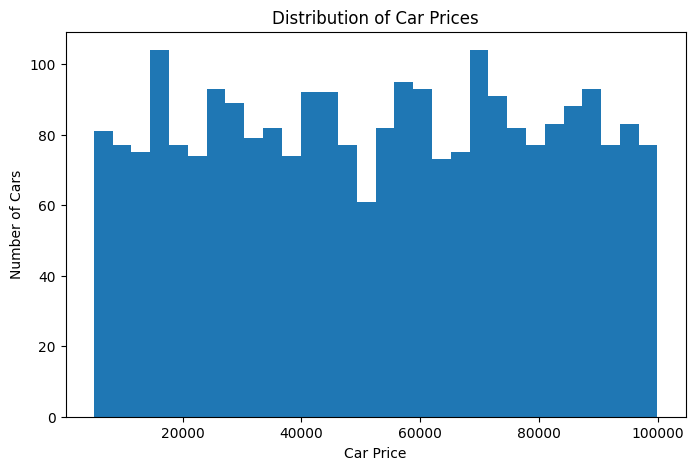

In [17]:
plt.figure(figsize=(8, 5))

plt.hist(df["Price"], bins=30)

plt.xlabel("Car Price")
plt.ylabel("Number of Cars")
plt.title("Distribution of Car Prices")

plt.show()

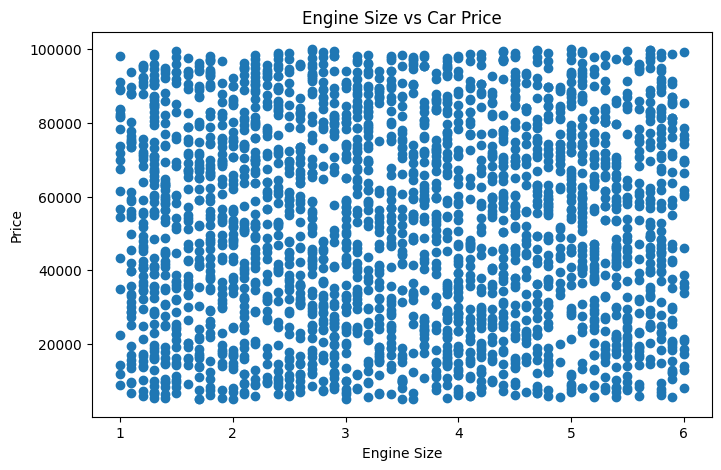

In [18]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Engine Size"],
    df["Price"]
)

plt.xlabel("Engine Size")
plt.ylabel("Price")
plt.title("Engine Size vs Car Price")

plt.show()

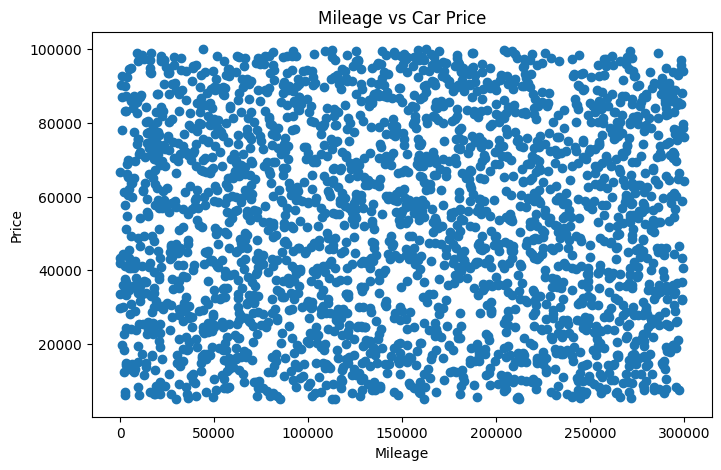

In [19]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Mileage"],
    df["Price"]
)

plt.xlabel("Mileage")
plt.ylabel("Price")
plt.title("Mileage vs Car Price")

plt.show()

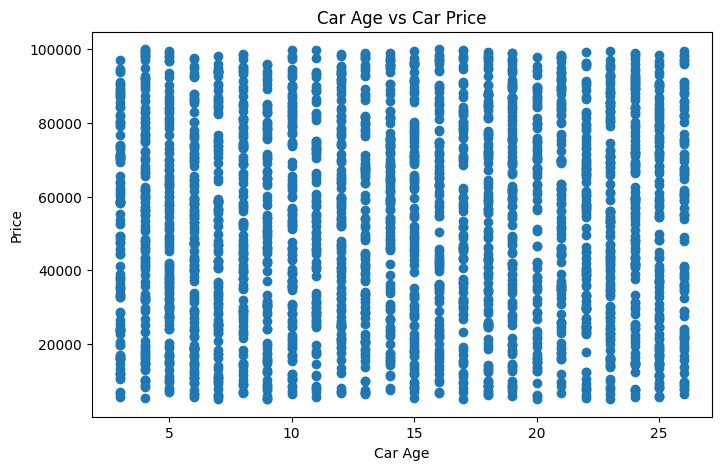

In [20]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Car_Age"],
    df["Price"]
)

plt.xlabel("Car Age")
plt.ylabel("Price")
plt.title("Car Age vs Car Price")

plt.show()

In [21]:
brand_prices = (
    df.groupby("Brand")["Price"]
    .mean()
    .sort_values(ascending=False)
)

print(brand_prices)

Brand
BMW         54157.114385
Tesla       53475.547471
Mercedes    53191.090085
Toyota      52078.728235
Honda       52050.283949
Audi        51953.424810
Ford        51593.254813
Name: Price, dtype: float64


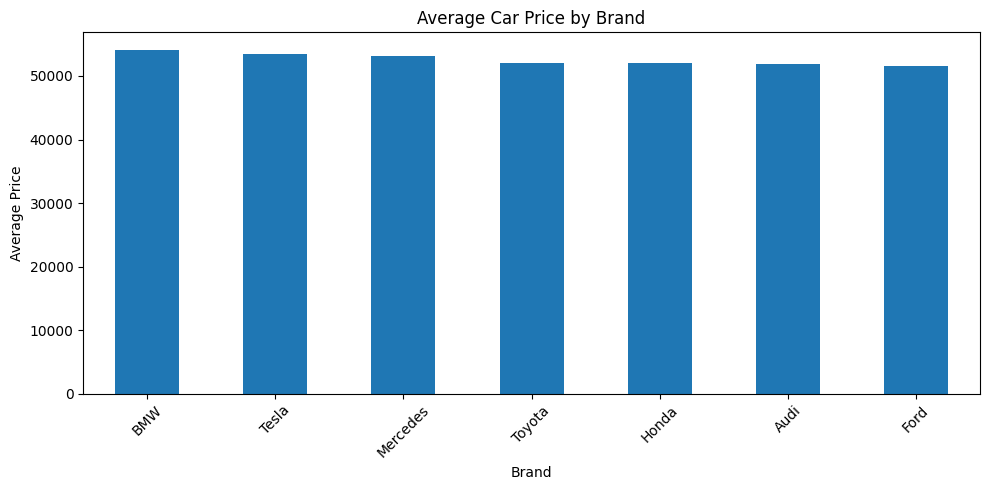

In [22]:
plt.figure(figsize=(10, 5))

brand_prices.plot(kind="bar")

plt.xlabel("Brand")
plt.ylabel("Average Price")
plt.title("Average Car Price by Brand")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [23]:
fuel_prices = (
    df.groupby("Fuel Type")["Price"]
    .mean()
    .sort_values(ascending=False)
)

print(fuel_prices)

Fuel Type
Diesel      54996.997588
Hybrid      52547.394759
Petrol      51767.918016
Electric    51103.013534
Name: Price, dtype: float64


In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

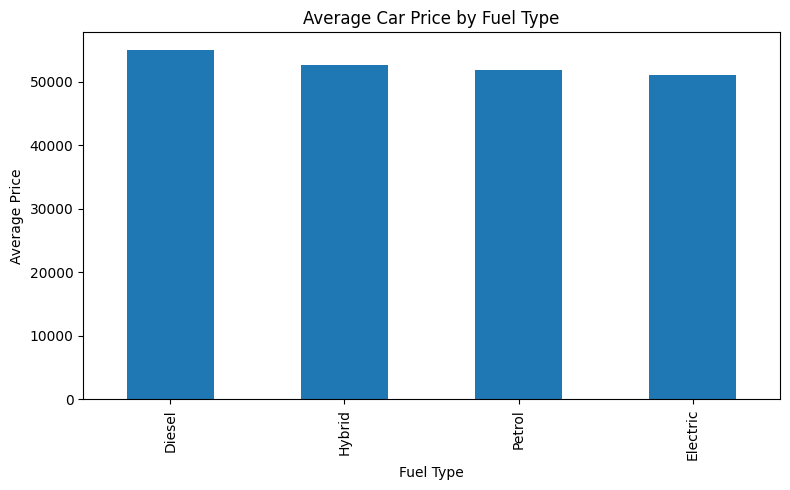

In [24]:
plt.figure(figsize=(8, 5))

fuel_prices.plot(kind="bar")

plt.xlabel("Fuel Type")
plt.ylabel("Average Price")
plt.title("Average Car Price by Fuel Type")

plt.tight_layout()
plt.show()

In [36]:
from sklearn.model_selection import train_test_split

In [25]:
condition_prices = (
    df.groupby("Condition")["Price"]
    .mean()
    .sort_values(ascending=False)
)

print(condition_prices)

Condition
Like New    53518.746376
Used        52470.919076
New         51904.509951
Name: Price, dtype: float64


In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

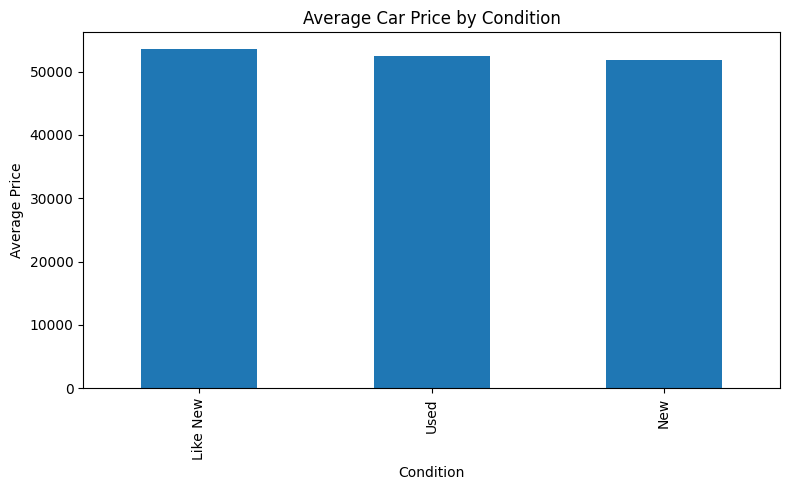

In [26]:
plt.figure(figsize=(8, 5))

condition_prices.plot(kind="bar")

plt.xlabel("Condition")
plt.ylabel("Average Price")
plt.title("Average Car Price by Condition")

plt.tight_layout()
plt.show()

In [27]:
y = df["Price"]

In [28]:
features = [
    "Brand",
    "Engine Size",
    "Fuel Type",
    "Transmission",
    "Mileage",
    "Condition",
    "Model",
    "Car_Age"
]

X = df[features]
y = df["Price"]

In [29]:
categorical_features = [
    "Brand",
    "Fuel Type",
    "Transmission",
    "Condition",
    "Model"
]

In [30]:
numerical_features = [
    "Engine Size",
    "Mileage",
    "Car_Age"
]

In [33]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="passthrough"
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [34]:
categorical_features = [
    "Brand",
    "Fuel Type",
    "Transmission",
    "Condition",
    "Model"
]

In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 2000
Testing rows: 500


In [39]:
linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

linear_model.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Brand', 'Fuel Type',
                                                   'Transmission', 'Condition',
                                                   'Model'])])),
                ('model', LinearRegression())])

In [40]:
y_pred_linear = linear_model.predict(X_test)

In [41]:
mae_linear = mean_absolute_error(
    y_test,
    y_pred_linear
)

rmse_linear = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_linear
    )
)

r2_linear = r2_score(
    y_test,
    y_pred_linear
)

print("Linear Regression")
print("------------------")
print("MAE :", mae_linear)
print("RMSE:", rmse_linear)
print("R²  :", r2_linear)

Linear Regression
------------------
MAE : 23742.522990748643
RMSE: 27526.01612887848
R²  : -0.00016927077988726502


In [42]:
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=200,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

rf_model.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Brand', 'Fuel Type',
                                                   'Transmission', 'Condition',
                                                   'Model'])])),
                ('model',
                 RandomForestRegressor(n_estimators=200, n_jobs=-1,
                                       random_state=42))])

In [43]:
y_pred_rf = rf_model.predict(X_test)

In [44]:
mae_rf = mean_absolute_error(
    y_test,
    y_pred_rf
)

rmse_rf = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_rf
    )
)

r2_rf = r2_score(
    y_test,
    y_pred_rf
)

print("Random Forest Regression")
print("-------------------------")
print("MAE :", mae_rf)
print("RMSE:", rmse_rf)
print("R²  :", r2_rf)

Random Forest Regression
-------------------------
MAE : 24559.370611599996
RMSE: 28514.78151575504
R²  : -0.07331422124417997


In [45]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest Regression"
    ],
    "MAE": [
        mae_linear,
        mae_rf
    ],
    "RMSE": [
        rmse_linear,
        rmse_rf
    ],
    "R2 Score": [
        r2_linear,
        r2_rf
    ]
})

results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,23742.522991,27526.016129,-0.000169
1,Random Forest Regression,24559.370612,28514.781516,-0.073314


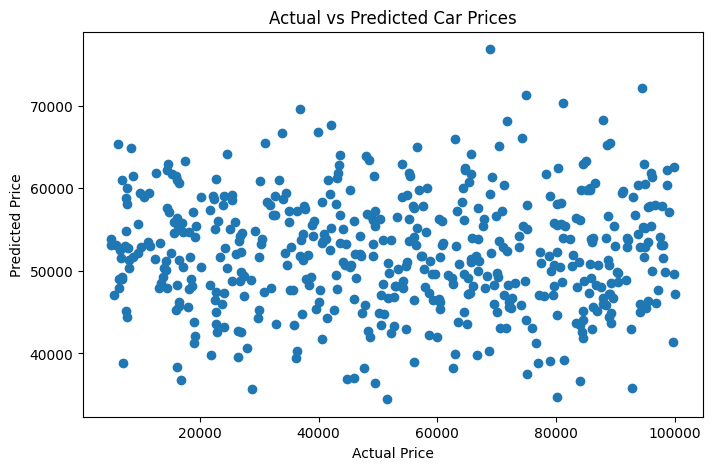

In [46]:
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    y_pred_rf
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Car Prices")

plt.show()

In [47]:
sample = X_test.iloc[[0]]

actual_price = y_test.iloc[0]

predicted_price = rf_model.predict(sample)[0]

print("Actual Price:", actual_price)
print("Predicted Price:", predicted_price)

Actual Price: 17494.9
Predicted Price: 63317.75269999996


## Model Evaluation

Two regression models were evaluated:

- Linear Regression
- Random Forest Regression

The models were evaluated using:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R² Score

The model comparison is shown in the results table above.

## Key Findings

The exploratory analysis was used to examine relationships between car price and variables such as engine size, mileage, car age, brand, fuel type, and condition.

The trained regression models were then evaluated on previously unseen test data to measure their price-prediction performance.

The final model selection is based on the observed test-set evaluation metrics.